<a href="https://colab.research.google.com/github/hardjac23/mis433/blob/main/churn_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive

drive.mount('/content/drive')
data_dir = '/content/drive/My Drive/Colab Notebooks/churn/'
output_dir = '/content/drive/My Drive/Colab Notebooks/output/'
os.makedirs(output_dir, exist_ok=True)

Mounted at /content/drive


In [ ]:
train = pd.read_csv(data_dir + 'churn_train.csv')
test = pd.read_csv(data_dir + 'churn_test.csv')
accounts = pd.read_csv(data_dir + 'accounts.csv')
demographics = pd.read_csv(data_dir + 'demographics.csv')
services = pd.read_csv(data_dir + 'services.csv')

In [ ]:
for name, d in [('train', train), ('test', test), ('accounts', accounts),
                ('demographics', demographics), ('services', services)]:
    print(name, d.shape)

train (4238, 2)
test (1060, 1)
accounts (5298, 8)
demographics (5298, 8)
services (47682, 3)


In [ ]:
accounts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerNo         5298 non-null   int64  
 1   BaseCharges        5298 non-null   float64
 2   DOC                5298 non-null   object 
 3   TotalCharges       5288 non-null   float64
 4   DOE                5298 non-null   object 
 5   ElectronicBilling  5298 non-null   object 
 6   ContractType       5293 non-null   object 
 7   PaymentMethod      5298 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 331.3+ KB


In [ ]:
accounts.describe(include='all')

,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
count,5298.000000,5298.000000,5298,5288.000000,5298,5298,5293,5298
unique,NaN,NaN,1,NaN,73,2,3,4
top,NaN,NaN,5-1-2012,NaN,6-Dec-11,Yes,Month-to-month,Electronic check
freq,NaN,NaN,5298,NaN,423,3120,2779,1586
mean,3849.500000,325.467205,NaN,11928.354056,NaN,NaN,NaN,NaN
std,1529.545194,151.352954,NaN,11486.453199,NaN,NaN,NaN,NaN
min,1201.000000,91.250000,NaN,94.250000,NaN,NaN,NaN,NaN
25%,2525.250000,178.250000,NaN,2314.937500,NaN,NaN,NaN,NaN
50%,3849.500000,352.500000,NaN,7377.500000,NaN,NaN,NaN,NaN
75%,5173.750000,451.250000,NaN,19992.812500,NaN,NaN,NaN,NaN


In [ ]:
demographics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerNo     5298 non-null   int64 
 1   Country        5298 non-null   object
 2   State          5298 non-null   object
 3   Retired        5298 non-null   int64 
 4   HasPartner     5298 non-null   int64 
 5   HasDependents  5298 non-null   int64 
 6   Education      5288 non-null   object
 7   Gender         5294 non-null   object
dtypes: int64(4), object(4)
memory usage: 331.3+ KB


In [ ]:
demographics.describe(include='all')

,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
count,5298.000000,5298,5298,5298.000000,5298.000000,5298.000000,5288,5294
unique,NaN,2,2,NaN,NaN,NaN,5,2
top,NaN,India,Maharashtra,NaN,NaN,NaN,Highschool or below,Male
freq,NaN,5293,5290,NaN,NaN,NaN,1426,2656
mean,3849.500000,NaN,NaN,0.158362,1.502454,1.690827,NaN,NaN
std,1529.545194,NaN,NaN,0.365114,0.500041,0.462196,NaN,NaN
min,1201.000000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN
25%,2525.250000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN
50%,3849.500000,NaN,NaN,0.000000,2.000000,2.000000,NaN,NaN
75%,5173.750000,NaN,NaN,0.000000,2.000000,2.000000,NaN,NaN


In [ ]:
services.head(12)

,CustomerNo,TypeOfService,SeviceDetails
0,1201,DeviceProtection,Yes
1,1201,HasPhoneService,1
2,1201,InternetServiceCategory,Fiber optic
3,1201,MultipleLines,No
4,1201,OnlineBackup,No
5,1201,OnlineSecurity,No
6,1201,StreamingMovies,Yes
7,1201,StreamingTelevision,Yes
8,1201,TechnicalSupport,No
9,1202,DeviceProtection,No internet service


In [ ]:
print(accounts.isnull().sum())
print(demographics.isnull().sum())

CustomerNo            0
BaseCharges           0
DOC                   0
TotalCharges         10
DOE                   0
ElectronicBilling     0
ContractType          5
PaymentMethod         0
dtype: int64
CustomerNo        0
Country           0
State             0
Retired           0
HasPartner        0
HasDependents     0
Education        10
Gender            4
dtype: int64


In [ ]:
services_wide = services.pivot(index='CustomerNo', columns='TypeOfService', values='SeviceDetails').reset_index()
services_wide.head()

TypeOfService,CustomerNo,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1203,No,1,Fiber optic,No,No,No,Yes,No,No
3,1204,No,1,DSL,Yes,Yes,Yes,No,No,Yes
4,1205,No,1,Fiber optic,Yes,No,No,No,No,No


In [ ]:
services_wide.shape

(5298, 10)

In [ ]:
train_df = (train.merge(accounts, on='CustomerNo', how='left')
                 .merge(demographics, on='CustomerNo', how='left')
                 .merge(services_wide, on='CustomerNo', how='left'))

test_df = (test.merge(accounts, on='CustomerNo', how='left')
               .merge(demographics, on='CustomerNo', how='left')
               .merge(services_wide, on='CustomerNo', how='left'))

print(train_df.shape, test_df.shape)
train_df.head()

(4238, 25) (1060, 24)


,CustomerNo,Churn,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod,Country,...,Gender,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,0,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check,India,...,Male,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,0,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check,India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1205,1,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check,India,...,Female,No,1,Fiber optic,Yes,No,No,No,No,No
3,1206,0,99.50,5-1-2012,6775.50,7-Mar-06,Yes,Two year,Credit card (automatic),India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
4,1207,0,91.25,5-1-2012,2673.50,17-Sep-09,No,One year,Credit card (automatic),India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service


In [ ]:
train_df['Churn'].value_counts(normalize=True)

,proportion
Churn,
0,0.752478
1,0.247522


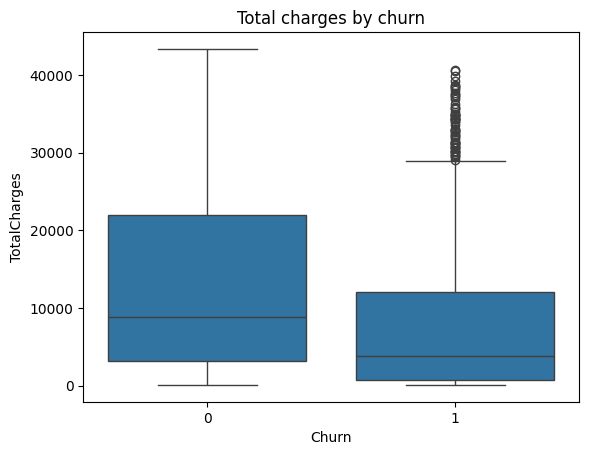

In [ ]:
fig, ax = plt.subplots()
sns.boxplot(data=train_df, x='Churn', y='TotalCharges', ax=ax)
ax.set_title("Total charges by churn")
plt.show()

In [ ]:
train_df.groupby('ContractType')['Churn'].mean()

,Churn
ContractType,
Month-to-month,0.410291
One year,0.109902
Two year,0.027752


In [ ]:
train_df.groupby('ContractType')

In [ ]:
train_df['Churn'].mean()

np.float64(0.24752241623407267)

In [ ]:
cols1 = ['BaseCharges', 'TotalCharges']
median = train_df['TotalCharges'].median()

X1 = train_df[cols1].fillna(median)
y = train_df['Churn']

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree1 = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
tree1.fit(X1, y)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

In [ ]:
tree1.score(X1, y)

0.7935346861727229

In [ ]:
X1_test = test_df[cols1].fillna(median)

y_hat1 = tree1.predict(X1_test).astype(int)
pd.Series(y_hat1).value_counts()

,count
0,914
1,146


In [ ]:
model1_submit = pd.DataFrame({
    'CustomerNo': test_df['CustomerNo'],
    'Churn': y_hat1,
})
model1_submit.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [ ]:
model1_submit.to_csv(f'{output_dir}/model1_tree_submit.csv', index=False)

In [ ]:
num_cols2 = ['BaseCharges', 'TotalCharges']
cat_cols2 = ['ContractType']

X2_num = train_df[num_cols2].fillna(median)

mode_contract = train_df['ContractType'].mode()[0]
X2_cat = train_df[cat_cols2].fillna({'ContractType': mode_contract})
mode_contract

'Month-to-month'

In [ ]:
from sklearn.preprocessing import OneHotEncoder

onehot_encoder = OneHotEncoder()
X2_cat_onehot = onehot_encoder.fit_transform(X2_cat).toarray()

column_names = onehot_encoder.get_feature_names_out()
X2_cat_onehot = pd.DataFrame(X2_cat_onehot, columns=column_names)
X2_cat_onehot.head()

,ContractType_Month-to-month,ContractType_One year,ContractType_Two year
0,0.0,1.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,0.0,0.0,1.0
4,0.0,1.0,0.0


In [ ]:
X2 = pd.concat([X2_num, X2_cat_onehot], axis=1)
X2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 5 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   BaseCharges                  4238 non-null   float64
 1   TotalCharges                 4238 non-null   float64
 2   ContractType_Month-to-month  4238 non-null   float64
 3   ContractType_One year        4238 non-null   float64
 4   ContractType_Two year        4238 non-null   float64
dtypes: float64(5)
memory usage: 165.7 KB


In [ ]:
tree2 = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
tree2.fit(X2, y)
tree2.score(X2, y)

0.7961302501179802

In [ ]:
X2_test_num = test_df[num_cols2].fillna(median)
X2_test_cat = test_df[cat_cols2].fillna({'ContractType': mode_contract})

X2_test_cat_onehot = pd.DataFrame(onehot_encoder.transform(X2_test_cat).toarray(), columns=column_names)
X2_test = pd.concat([X2_test_num, X2_test_cat_onehot], axis=1)

print(list(X2_test.columns) == list(X2.columns))

True


In [ ]:
y_hat2 = tree2.predict(X2_test).astype(int)
pd.Series(y_hat2).value_counts()

,count
0,921
1,139


In [ ]:
model2_submit = pd.DataFrame({'CustomerNo': test_df['CustomerNo'], 'Churn': y_hat2})
model2_submit.to_csv(f'{output_dir}/model2_tree_onehot_submit.csv', index=False)
model2_submit.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [ ]:
num_cols3 = ['BaseCharges', 'TotalCharges']
cat_cols3 = ['ContractType', 'PaymentMethod', 'InternetServiceCategory']

X3_num = train_df[num_cols3].fillna(median)
X3_cat = train_df[cat_cols3].fillna({'ContractType': mode_contract})

X3_cat.isnull().sum()

,0
ContractType,0
PaymentMethod,0
InternetServiceCategory,0


In [ ]:
onehot_encoder3 = OneHotEncoder()
X3_cat_onehot = onehot_encoder3.fit_transform(X3_cat).toarray()

column_names3 = onehot_encoder3.get_feature_names_out()
X3_cat_onehot = pd.DataFrame(X3_cat_onehot, columns=column_names3)
X3_cat_onehot.head()

,ContractType_Month-to-month,ContractType_One year,ContractType_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetServiceCategory_DSL,InternetServiceCategory_Fiber optic,InternetServiceCategory_No
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
X3 = pd.concat([X3_num, X3_cat_onehot], axis=1)
X3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 12 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   BaseCharges                              4238 non-null   float64
 1   TotalCharges                             4238 non-null   float64
 2   ContractType_Month-to-month              4238 non-null   float64
 3   ContractType_One year                    4238 non-null   float64
 4   ContractType_Two year                    4238 non-null   float64
 5   PaymentMethod_Bank transfer (automatic)  4238 non-null   float64
 6   PaymentMethod_Credit card (automatic)    4238 non-null   float64
 7   PaymentMethod_Electronic check           4238 non-null   float64
 8   PaymentMethod_Mailed check               4238 non-null   float64
 9   InternetServiceCategory_DSL              4238 non-null   float64
 10  InternetServiceCategory_Fiber optic      4238 no

In [ ]:
tree3 = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
tree3.fit(X3, y)
tree3.score(X3, y)

0.8008494572911751

In [ ]:
X3_test_num = test_df[num_cols3].fillna(median)
X3_test_cat = test_df[cat_cols3].fillna({'ContractType': mode_contract})

X3_test_cat_onehot = pd.DataFrame(onehot_encoder3.transform(X3_test_cat).toarray(), columns=column_names3)
X3_test = pd.concat([X3_test_num, X3_test_cat_onehot], axis=1)

print(list(X3_test.columns) == list(X3.columns))

True


In [ ]:
y_hat3 = tree3.predict(X3_test).astype(int)
pd.Series(y_hat3).value_counts()

,count
0,929
1,131


In [ ]:
model3_submit = pd.DataFrame({'CustomerNo': test_df['CustomerNo'], 'Churn': y_hat3})
model3_submit.to_csv(f'{output_dir}/model3_tree_onehot_submit.csv', index=False)
model3_submit.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0
